# Report vendite fertilizzanti e biostimolanti
Un'azienda sarda che vende fertilizzanti e biostimolanti alle aziende agricole, richiede un report delle vendite per gli anni 2024 e 2025. Il responsabile commerciale ha fornito le seguenti tabelle contenenti dati simulati:
- ordini: informazioni sugli ordini effettuati nel periodo 2024/2025 con le colonne id_ordine | data_ordine | id_cliente | codice_prodotto | quantita | unita | prezzo_unitario_eur
- clienti: dati dei clienti con le colonne id_cliente | ragione_sociale | provincia | coltura_principale | ettari
- prodotti: dettagli sui prodotti venduti con le colonne codice_prodotto | nome | categoria | unita | prezzo_listino

Prima di poter essere utilizzate per le analisi le tabelle devono essere sistemate e pulite. 

# 1. # ========================== CARICARE E ISPEZIONARE LE TABELLE ==========================

In [2]:
# Import librerie
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Caricare i datasets
ordini = pd.read_csv("dati/ordini.csv")
clienti = pd.read_csv("dati/clienti.csv")
prodotti = pd.read_csv("dati/prodotti.csv")

# ========================== ORDINI ==========================

In [4]:
# Esplorare la tabella ordini
print("------ TABELLA ORDINI ------")
print(ordini.info())

# Ispezionare la presenza di valori mancanti
print("\nValori mancanti per colonna:")
print(ordini.isna().sum())

# Ispezionare la presenza di righe duplicate
print(f'\nRighe duplicate: {ordini.duplicated().sum()}')

------ TABELLA ORDINI ------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 936 entries, 0 to 935
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_ordine            936 non-null    object 
 1   data_ordine          936 non-null    object 
 2   id_cliente           936 non-null    object 
 3   codice_prodotto      936 non-null    object 
 4   quantita             936 non-null    int64  
 5   unita                936 non-null    object 
 6   prezzo_unitario_eur  909 non-null    float64
dtypes: float64(1), int64(1), object(5)
memory usage: 51.3+ KB
None

Valori mancanti per colonna:
id_ordine               0
data_ordine             0
id_cliente              0
codice_prodotto         0
quantita                0
unita                   0
prezzo_unitario_eur    27
dtype: int64

Righe duplicate: 36


In [5]:
# Esplorare le righe con valori mancanti della tabella ordini
mancanti_ordini = ordini[ordini["prezzo_unitario_eur"].isna()]
mancanti_ordini

,id_ordine,data_ordine,id_cliente,codice_prodotto,quantita,unita,prezzo_unitario_eur
4,ORD00848,2024-01-05,C112,NUT-NPK1,216,kg,NaN
26,ORD00442,2024-01-23,C058,NUT-NPK1,571,kg,NaN
35,ORD00468,2024-01-26,C062,NUT-FE03,737,kg,NaN
40,ORD00275,2024-01-28,C036,NUT-NPK1,487,kg,NaN
50,ORD00181,2024-02-05,C025,BIO-MX03,36,L,NaN
132,ORD00536,2024-04-04,C073,BIO-MX03,51,L,NaN
206,ORD00591,2024-05-21,C079,NUT-ZN04,1445,kg,NaN
253,ORD00071,2024-06-28,C010,NUT-FE03,321,kg,NaN
301,ORD00606,2024-07-31,C081,NUT-ZN04,736,kg,NaN
330,ORD00382,2024-08-16,C049,BIO-PH01,28,L,NaN


In [6]:
# Esplorare le righe duplicate della tabella ordini
duplicati_ordini = ordini[ordini.duplicated(keep=False)]
duplicati_ordini

,id_ordine,data_ordine,id_cliente,codice_prodotto,quantita,unita,prezzo_unitario_eur
29,ORD00777,2024-01-23,C101,BIO-MX03,19,L,16.2
30,ORD00777,2024-01-23,C101,BIO-MX03,19,L,16.2
54,ORD00437,2024-02-07,C057,BIO-PH01,40,L,12.5
55,ORD00437,2024-02-07,C057,BIO-PH01,40,L,12.5
66,ORD00129,2024-02-13,C019,BIO-PH01,56,L,12.5
...,...,...,...,...,...,...,...
813,ORD00450,2025-09-15,C060,NUT-FE03,805,kg,9.8
844,ORD00865,2025-10-12,C115,NUT-FE03,1540,kg,9.8
845,ORD00865,2025-10-12,C115,NUT-FE03,1540,kg,9.8
931,ORD00646,2025-12-28,C087,NUT-NPK1,633,kg,1.1


In [7]:
# Esplorare la colonna id_ordine della tabella ordini
print("------ TABELLA ORDINI ------")
print(f'\nNumero di righe duplicate: {ordini.duplicated(subset=["id_ordine"]).sum()}')

# Controllare la colonna unità
print(f'\nNumero di ordini per unità di misura: {ordini["unita"].value_counts()}')

# Controllare il valore minimo della colonna quantità
print(f'\nValore minimo quantità vendute: {ordini["quantita"].min()}')

# Ordinare la colonna quantità in ordine ascendente per individuare ordini con quantità negativa
quantita_negative = ordini[ordini["quantita"] < 0]
print(f'Numero di ordini con quantità negativa: {quantita_negative["id_ordine"].count()}')

------ TABELLA ORDINI ------

Numero di righe duplicate: 37

Numero di ordini per unità di misura: unita
kg     464
L      371
KG      29
Kg      23
kg      22
Lt      16
L       11
Name: count, dtype: int64

Valore minimo quantità vendute: -2439
Numero di ordini con quantità negativa: 39


# L'esplorazione della tabella ordini evidenzia un problema di formattazione delle unità di misura. Per esempio l'unita dei litri compare nella tabella come "L", "L " e "Lt".

In [8]:
# Esplorare la tabella degli ordini con quantità negative
quantita_negative.sort_values("quantita")

,id_ordine,data_ordine,id_cliente,codice_prodotto,quantita,unita,prezzo_unitario_eur
191,ORD00872,2024-05-11,C117,NUT-ZN04,-2439,kg,11.20
603,ORD00509,2025-03-11,C070,NUT-UR02,-2100,kg,0.75
727,ORD00734,2025-06-24,C096,NUT-NPK1,-2028,kg,0.99
428,ORD00578,2024-10-21,C077,NUT-UR02,-1480,kg,0.68
298,ORD00513,2024-07-30,C070,NUT-FE03,-1431,KG,9.80
574,ORD00131,2025-02-15,C019,NUT-NPK1,-1198,kg,1.04
71,ORD00012,2024-02-17,C003,NUT-ZN04,-1183,kg,10.08
209,ORD00114,2024-05-26,C017,NUT-ZN04,-1139,kg,11.20
370,ORD00496,2024-09-13,C068,NUT-UR02,-1084,kg,0.75
757,ORD00228,23/07/2025,C031,NUT-FE03,-1073,kg,9.80


# Gli ordini con quantità negative potrebbero essere dovuti a un errore nell'immissione dei dati o corrispondere a dei resi. Per testare la seconda ipotesi vengono analizzati tutti gli ordini effettuati dal cliente C117, che ha effettuato un ordine con -2439 kg del prodotto NUT-ZN04 nel 2024.  

In [9]:
# Filtrare gli ordini per il cliente C117 e il codice prodotto NUT-ZN04
cliente_C117 = ordini[(ordini["id_cliente"] == "C117") & (ordini["codice_prodotto"] == "NUT-ZN04")]
cliente_C117

,id_ordine,data_ordine,id_cliente,codice_prodotto,quantita,unita,prezzo_unitario_eur
0,ORD00870,2024-01-01,C117,NUT-ZN04,1763,kg,11.2
173,ORD00871,2024-04-30,C117,NUT-ZN04,2439,kg,11.2
191,ORD00872,2024-05-11,C117,NUT-ZN04,-2439,kg,11.2


# La tabella evidenzia come l'ordine ORD00872 con -2439 kg di NUT-ZN04 corrisponda ad un reso dell'ordine ORD00871 effettuato dallo stesso cliente, 11 giorni prima.

In [10]:
# Ordinare la tabella cronologicamente
ordini.sort_values("data_ordine").head(20)

,id_ordine,data_ordine,id_cliente,codice_prodotto,quantita,unita,prezzo_unitario_eur
360,ORD00853,04/09/2024,C113,NUT-ZN04,1361,kg,10.08
491,ORD00189,04/12/2024,C026,BIO-MX03,14,L,18.00
592,ORD00693,05/03/2025,C092,NUT-UR02,1911,kg,0.75
837,ORD00120,06/10/2025,C018,BIO-PH01,-16,L,12.50
445,ORD00373,06/11/2024,C048,NUT-ZN04,1704,kg,10.08
136,ORD00851,07/04/2024,C113,BIO-MX03,49,L,18.00
409,ORD00344,08/10/2024,C045,NUT-NPK1,2018,kg,1.10
0,ORD00870,2024-01-01,C117,NUT-ZN04,1763,kg,11.20
2,ORD00775,2024-01-02,C101,BIO-PH01,43,L,12.50
1,ORD00208,2024-01-02,C029,NUT-ZN04,1308,Kg,11.20


# La colonna data_ordine presenta diverse formattazioni per indicare le date: YYYY-MM-DD e DD/MM/YYYY.

# ========================== CLIENTI ==========================

In [11]:
# Esplorare la tabella clienti
print("------ TABELLA CLIENTI ------")
print(clienti.info())

# Ispezionare la presenza di valori mancanti
print("\nValori mancanti per colonna:")
print(clienti.isna().sum())

# Ispezionare la presenza di righe duplicate
print(f'\nRighe duplicate: {clienti.duplicated().sum()}')


------ TABELLA CLIENTI ------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id_cliente          120 non-null    object
 1   ragione_sociale     120 non-null    object
 2   provincia           120 non-null    object
 3   coltura_principale  120 non-null    object
 4   ettari              120 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 4.8+ KB
None

Valori mancanti per colonna:
id_cliente            0
ragione_sociale       0
provincia             0
coltura_principale    0
ettari                0
dtype: int64

Righe duplicate: 0


In [12]:
# Esplorare la colonna province
print("Numero di clienti per provincia:")
print(clienti["provincia"].value_counts())

Numero di clienti per provincia:
provincia
Cagliari        14
SS              14
SS              13
SU              10
Sud Sardegna     9
Nuoro            9
Oristano         9
OR               9
CA               8
Sassari          7
sassari          7
NU               6
oristano         5
Name: count, dtype: int64


# L'esplorazione della tabella clienti evidenzia un problema di formattazione delle province che vengono indicate con il loro nome esteso o con la sigla.

# ========================== PRODOTTI ==========================

In [13]:
# Esplorare la tabella prodotti
print("------ TABELLA PRODOTTI ------")
print(prodotti.info())

# Ispezionare la presenza di valori mancanti
print("\nValori mancanti per colonna:")
print(prodotti.isna().sum())

# Ispezionare la presenza di righe duplicate
print(f'\nRighe duplicate: {prodotti.duplicated().sum()}')

------ TABELLA PRODOTTI ------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   codice_prodotto  7 non-null      object 
 1   nome             7 non-null      object 
 2   categoria        7 non-null      object 
 3   unita            7 non-null      object 
 4   prezzo_listino   7 non-null      float64
dtypes: float64(1), object(4)
memory usage: 412.0+ bytes
None

Valori mancanti per colonna:
codice_prodotto    0
nome               0
categoria          0
unita              0
prezzo_listino     0
dtype: int64

Righe duplicate: 0


# 2. ========================== PULIRE LE TABELLE ==========================

In [14]:
# ----------- TABELLA ORDINI -----------
# Trasformare la colonna data ordine in formato date giorno/mese/anno
date_iso = pd.to_datetime(ordini["data_ordine"], format="%Y-%m-%d", errors="coerce")
date_ita = pd.to_datetime(ordini["data_ordine"], format="%d/%m/%Y", errors="coerce")
ordini["data_ordine"] = date_iso.fillna(date_ita)

# Controllare la presenza di valori nulli dopo la trasformazione delle date
print(f'Valori mancanti nella colonna data_ordine: {ordini["data_ordine"].isna().sum()}')

# Controllare la presenza di righe duplicate dopo la trasformazione delle date
print(f'Righe duplicate dopo la trasformazione della colonna data_ordine: {ordini.duplicated().sum()}')


Valori mancanti nella colonna data_ordine: 0
Righe duplicate dopo la trasformazione della colonna data_ordine: 37


# Dopo aver uniformato la colonna data_ordine, il numero di righe duplicate della tabella ordini è aumentato di 1.

In [15]:
# Eliminare le righe duplicate dalla tabella ordini
ordini = ordini.drop_duplicates().copy()

# Controllare la tabella ordini pulita
ordini.shape

## Controllare la presenza di duplicati
print(f'Numero di righe duplicate: {ordini.duplicated(subset=["id_ordine"]).sum()}')

# Sistemare la formattazione della colonna unità nella tabella ordini
ordini["unita"] = ordini["unita"].str.strip().str.lower().replace({"l": "L", "lt": "L"})

# # Ricontrollare le unità della colonna unità della tabella ordini
print("Numero di ordini per unità di misura:")
print(ordini["unita"].value_counts())

Numero di righe duplicate: 0
Numero di ordini per unità di misura:
unita
kg    518
L     381
Name: count, dtype: int64


In [16]:
# ----------- TABELLA CLIENTI -----------
# Sistemare la formattazione delle province della tabella clienti
clienti["provincia"] = clienti["provincia"].str.strip().str.upper().replace({"SASSARI": "SS", "CAGLIARI": "CA", "ORISTANO": "OR", "NUORO": "NU", "SUD SARDEGNA": "SU"})
print("Numero di clienti per provincia:")
print(clienti["provincia"].value_counts())

Numero di clienti per provincia:
provincia
SS    41
OR    23
CA    22
SU    19
NU    15
Name: count, dtype: int64


In [17]:
# ----------- PREZZI MANCANTI STIMATI DAL LISTINO -----------
# Unire la tabella ordini con la tabella prodotti per recuperare i prezzi mancanti
prezzi_stimati = pd.merge(ordini, prodotti[["codice_prodotto", "prezzo_listino"]], on="codice_prodotto", how="left")

# Recuperare i prezzi mancanti
prezzi_stimati["prezzo_stimato"] = prezzi_stimati["prezzo_unitario_eur"].isna()
prezzi_stimati["prezzo_unitario_eur"] = prezzi_stimati["prezzo_unitario_eur"].fillna(prezzi_stimati["prezzo_listino"])

# Controllare la colonna prezzo_stimato
print(f'Ordini con prezzo stimato: {prezzi_stimati["prezzo_stimato"].sum()}')

# Controllare la presenza di valori mancanti nella colonna del prezzo unitario
print(f'Numero di prezzi mancanti: {prezzi_stimati["prezzo_unitario_eur"].isna().sum()}')

Ordini con prezzo stimato: 27
Numero di prezzi mancanti: 0


In [18]:
# Salvare la tabella ordini pulita con i prezzi stimati
prezzi_stimati.to_csv("dati/ordini_puliti.csv", index=False)
print("Tabella ordini_puliti.csv salvata correttamente.")

Tabella ordini_puliti.csv salvata correttamente.


# 3. ========================== CALCOLARE IL FATTURATO ==========================

In [19]:
# Creare il report finale
report_finale = prezzi_stimati.copy()
report_finale["importo"] = report_finale["quantita"] * report_finale["prezzo_unitario_eur"]
print("----------- FATTURATO 2024 E 2025 -----------" )
print(f'\nFatturato netto 2024-2025: {report_finale["importo"].sum():,.2f}€')

# Calcolare il fatturato annuale per il 2024 e per il 2025
report_finale["anno"] = report_finale["data_ordine"].dt.year
fatturato_annuale = report_finale.groupby("anno")["importo"].sum().reset_index()
f_2024 = fatturato_annuale.loc[fatturato_annuale["anno"] == 2024, "importo"].iloc[0]
f_2025 = fatturato_annuale.loc[fatturato_annuale["anno"] == 2025, "importo"].iloc[0]

print(f'Fatturato annuale 2024: {f_2024:,.2f}€')
print(f'Fatturato annuale 2025: {f_2025:,.2f}€')

# Calcolare la variazione % del fatturato 2024 rispetto a quello 2025
variazione = (f_2025 - f_2024) / f_2024 * 100
print(f'Variazione % fatturato 2025 rispetto al 2024: {variazione:.1f}%')

----------- FATTURATO 2024 E 2025 -----------

Fatturato netto 2024-2025: 4,585,932.26€
Fatturato annuale 2024: 2,651,716.37€
Fatturato annuale 2025: 1,934,215.89€
Variazione % fatturato 2025 rispetto al 2024: -27.1%


# 4. ========================== IDENTIFICARE LA POSSIBILE CAUSA DEL CALO DI FATTURATO ==========================

In [20]:
# 1. Testare l'ipotesi dei resi
resi = report_finale[report_finale["importo"] < 0]
resi = resi.groupby("anno")["importo"].sum().reset_index()
resi_2024 = resi.loc[resi["anno"] == 2024, "importo"].iloc[0]
resi_2025 = resi.loc[resi["anno"] == 2025, "importo"].iloc[0]
print("----------- RESI -----------")
print(f'\nImporto resi 2024: {resi_2024:,.2f}€')
print(f'Importo resi 2025: {resi_2025:,.2f}€')

# Calcolare la differenza di resi tra il 2024 e il 2025
differenza_resi_2025_2024 = resi_2025 - resi_2024
percentuale_riduzione_resi_2025 = differenza_resi_2025_2024 / resi_2024 * 100

print(f'Nel 2025 i resi sono diminuiti di {differenza_resi_2025_2024:,.2f}€')
print(f'Riduzione in percentuale dei resi nel 2025 rispetto al 2024: {percentuale_riduzione_resi_2025:.1f}%')

----------- RESI -----------

Importo resi 2024: -83,872.39€
Importo resi 2025: -31,127.82€
Nel 2025 i resi sono diminuiti di 52,744.57€
Riduzione in percentuale dei resi nel 2025 rispetto al 2024: -62.9%


# I resi non sono la causa principale del calo di vendite osservato nel 2025. Al contrario nel 2025 i resi sono diminuiti del 62,9% rispetto al 2024.

In [21]:
# 2. Testare l'ipotesi dei clienti persi
clienti_2024 = report_finale.loc[report_finale["anno"] == 2024, "id_cliente"].unique()
clienti_2025 = report_finale.loc[report_finale["anno"] == 2025, "id_cliente"].unique()
clienti_persi = clienti[(clienti["id_cliente"].isin(clienti_2024)) & (~clienti["id_cliente"].isin(clienti_2025))]

# Calcolare il fatturato dovuto ai clienti persi nel 2024
ordini_clienti_persi_2024 = report_finale[(report_finale["anno"] == 2024) & (report_finale["id_cliente"].isin(clienti_persi["id_cliente"]))]
fatturato_clienti_persi_2024 = ordini_clienti_persi_2024["importo"].sum()
print("----------- DISTRIBUZIONE DEI CLIENTI NEL 2024 -----------")
print(f'\nFatturato totale del 2024 dei clienti persi: {fatturato_clienti_persi_2024:,.2f}€')

# Calcolare la percentuale di perdita di fatturato nel 2025 dovuta ai clienti persi
calo_2025 = f_2025 - f_2024
percentuale_calo_da_clienti_persi_2025 = abs((fatturato_clienti_persi_2024 / calo_2025) * 100)
print(f'Percentuale calo fatturato 2025 spiegata dai soli clienti persi: {percentuale_calo_da_clienti_persi_2025:.1f}%')

# Calcolare la distribuzione delle province nei clienti totali e nei clienti persi
province_clienti_totali = clienti["provincia"].value_counts(normalize=True)
province_clienti_persi = clienti_persi["provincia"].value_counts(normalize=True)
print("\nDistribuzione delle province dei clienti totali:")
print(province_clienti_totali)

print("\nDistribuzione delle province dei clienti persi:")
print(province_clienti_persi)

# Calcolare la percentuale di clienti persi per provincia
clienti_attivi_2024 = clienti[clienti["id_cliente"].isin(clienti_2024)].copy()
clienti_attivi_2024["perso"] = ~clienti_attivi_2024["id_cliente"].isin(clienti_2025)
n_clienti_persi = clienti_attivi_2024["perso"].sum()
print(f'\nNumero di clienti persi nel 2025: {n_clienti_persi}')


----------- DISTRIBUZIONE DEI CLIENTI NEL 2024 -----------

Fatturato totale del 2024 dei clienti persi: 463,069.80€
Percentuale calo fatturato 2025 spiegata dai soli clienti persi: 64.5%

Distribuzione delle province dei clienti totali:
provincia
SS    0.341667
OR    0.191667
CA    0.183333
SU    0.158333
NU    0.125000
Name: proportion, dtype: float64

Distribuzione delle province dei clienti persi:
provincia
SS    0.470588
SU    0.235294
OR    0.176471
CA    0.058824
NU    0.058824
Name: proportion, dtype: float64

Numero di clienti persi nel 2025: 17


In [22]:
# Calcolare il numero di clienti iniziali nel 2024 e il numero di clienti persi nel 2025 per provincia
province_clienti_2024 = clienti_attivi_2024.groupby("provincia").agg(n_clienti=("id_cliente", "count"), n_persi=("perso", "sum")).reset_index()
n_clienti_persi_per_provincia = province_clienti_2024.set_index("provincia")["n_persi"].sort_values(ascending=False)
print("----------- ABBANDONO DEI CLIENTI PER PROVINCIA NEL 2025 ----------- ")
print("\nNumero di clienti persi per provincia:")
print(n_clienti_persi_per_provincia)

# Calcolare il tasso di abbandono dei clienti per provincia
province_clienti_2024["%_clienti_persi"] = ((province_clienti_2024["n_persi"] / province_clienti_2024["n_clienti"]) * 100).round(1)
perc_clienti_persi_per_provincia = province_clienti_2024.set_index("provincia")["%_clienti_persi"].sort_values(ascending=False)
print("\nTasso di abbandono dei clienti per provincia:")
print(perc_clienti_persi_per_provincia)

# Calcolare il fatturato nel 2024 per provincia dei clienti persi
ordini_con_province_clienti_persi_2024 = pd.merge(ordini_clienti_persi_2024, clienti[["id_cliente", "provincia"]], on="id_cliente", how="left")
fatturato_province_clienti_persi_2024 = ordini_con_province_clienti_persi_2024.groupby("provincia")["importo"].sum().reset_index(name="fatturato_clienti_persi")
print("\nFatturato 2024 dei clienti persi per provincia:")
print(fatturato_province_clienti_persi_2024)

----------- ABBANDONO DEI CLIENTI PER PROVINCIA NEL 2025 ----------- 

Numero di clienti persi per provincia:
provincia
SS    8
SU    4
OR    3
CA    1
NU    1
Name: n_persi, dtype: int64

Tasso di abbandono dei clienti per provincia:
provincia
SU    25.0
SS    21.1
OR    13.6
NU     6.7
CA     4.5
Name: %_clienti_persi, dtype: float64

Fatturato 2024 dei clienti persi per provincia:
  provincia  fatturato_clienti_persi
0        CA                  12474.8
1        NU                   2151.7
2        OR                  82044.0
3        SS                 201257.2
4        SU                 165142.1


In [ ]:
# MERGEfa
province_clienti_2024
fatturato_perso_2025

,provincia,n_clienti,n_persi,%_clienti_persi
0,CA,22,1,4.5
1,NU,15,1,6.7
2,OR,22,3,13.6
3,SS,38,8,21.1
4,SU,16,4,25.0


In [24]:
# Creare una tabella con tutti gli ordini del 2024
ordini_clienti_2024 = report_finale[report_finale["anno"] == 2024]
ordini_clienti_con_provincia_2024 = pd.merge(ordini_clienti_2024, clienti, on="id_cliente", how="left")

# Calcolare il fatturato di tutti i clienti per provincia nel 2024
fatturato_province_clienti_2024 = ordini_clienti_con_provincia_2024.groupby("provincia")["importo"].sum().reset_index(name="fatturato_totale")
fatturato_2024_per_provincia = fatturato_province_clienti_2024.set_index("provincia")["fatturato_totale"].sort_values(ascending=False)
print("----------- IMPATTO DEI CLIENTI PERSI SUL FATTURATO 2025 ----------- ")
print("\nFatturato 2024 per provincia:")
print(fatturato_2024_per_provincia)

# Calcolare il fatturato perso nel 2025 a causa dei clienti persi
fatturato_perso_2025 = pd.merge(fatturato_province_clienti_2024, fatturato_province_clienti_persi_2024, on="provincia", how="left").fillna(0)
fatturato_perso_2025["%_fatturato_perso"] = ((fatturato_perso_2025["fatturato_clienti_persi"] / fatturato_perso_2025["fatturato_totale"]) * 100).round(1)
fatturato_2025_perso_per_provincia = fatturato_perso_2025.set_index("provincia")["%_fatturato_perso"].sort_values(ascending=False)
print("\nPercentuale di fatturato perso nel 2025 per provincia a causa dei clienti persi:")
print(fatturato_2025_perso_per_provincia)

# Confrontare la percentuale di fatturato perso con la percentuale di perdita dei clienti per provincia
fatturato_e_clienti_persi_provincia = pd.merge(fatturato_perso_2025, province_clienti_2024[["provincia", "%_clienti_persi"]], on="provincia", how="left").fillna(0)
fatturato_perso_vs_clienti_persi_per_provincia = fatturato_e_clienti_persi_provincia.set_index("provincia")[["%_fatturato_perso", "%_clienti_persi"]].sort_values(by="%_fatturato_perso", ascending=False)
print("\nConfronto tra percentuale di fatturato perso e percentuale di clienti persi per provincia:")
print(fatturato_perso_vs_clienti_persi_per_provincia)

----------- IMPATTO DEI CLIENTI PERSI SUL FATTURATO 2025 ----------- 

Fatturato 2024 per provincia:
provincia
SS    907714.35
CA    562102.79
SU    481018.04
NU    429615.64
OR    271265.55
Name: fatturato_totale, dtype: float64

Percentuale di fatturato perso nel 2025 per provincia a causa dei clienti persi:
provincia
SU    34.3
OR    30.2
SS    22.2
CA     2.2
NU     0.5
Name: %_fatturato_perso, dtype: float64

Confronto tra percentuale di fatturato perso e percentuale di clienti persi per provincia:
           %_fatturato_perso  %_clienti_persi
provincia                                    
SU                      34.3             25.0
OR                      30.2             13.6
SS                      22.2             21.1
CA                       2.2              4.5
NU                       0.5              6.7


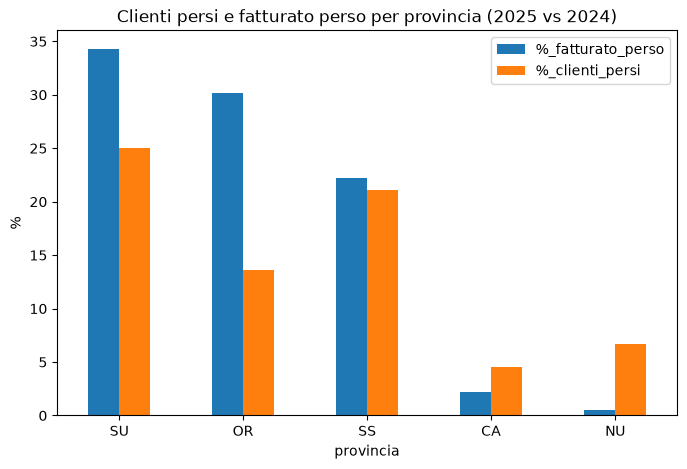

In [25]:
# Creare un grafico a barre che confronti per provincia percentuale di clienti persi e percentuale di fatturato perso
fatturato_perso_vs_clienti_persi_per_provincia.plot(kind="bar", figsize=(8, 5))
plt.ylabel("%")
plt.title("Clienti persi e fatturato perso per provincia (2025 vs 2024)")
plt.xticks(rotation=0)
plt.savefig("clienti_vs_fatturato_persi.png", dpi=150, bbox_inches="tight")
plt.show()

# La provincia di Oristano ha subito un calo di fatturato del 30,2% ma ha perso solo il 13,6% dei suoi clienti iniziali (3 clienti su 22).

In [26]:
# Calcolare il fatturato del 2024 per singolo cliente nella provincia di Oristano
clienti_oristano = ordini_clienti_con_provincia_2024[ordini_clienti_con_provincia_2024["provincia"] == "OR"]
best_clienti_oristano = clienti_oristano.groupby("id_cliente").agg(fatturato=("importo", "sum"), n_ordini=("id_ordine", "count")).reset_index()
best_clienti_oristano["perso"] = ~best_clienti_oristano["id_cliente"].isin(clienti_2025)
best_clienti_oristano.sort_values("fatturato", ascending=False)

,id_cliente,fatturato,n_ordini,perso
7,C048,35524.92,5,False
12,C067,31604.21,6,True
0,C010,27395.77,4,False
15,C077,27136.19,8,True
6,C038,25921.65,6,False
21,C117,23303.60,6,True
19,C111,18838.40,1,False
18,C096,18339.12,4,False
3,C018,11912.00,2,False
13,C069,11788.41,4,False


In [27]:
# Calcolare il fatturato nel 2024 dei clienti persi nella provincia di Oristano
best_clienti_oristano_persi = best_clienti_oristano[best_clienti_oristano["perso"] == True]
fatturato_clienti_persi_oristano = best_clienti_oristano_persi["fatturato"].sum()
print(f'Fatturato 2024 dei clienti persi nella provincia di Oristano: {fatturato_clienti_persi_oristano:,.2f}€')

Fatturato 2024 dei clienti persi nella provincia di Oristano: 82,044.00€


In [ ]:
# Creare una tabella riassuntiva finale
tabella_riassuntiva = pd.merge(province_clienti_2024, fatturato_perso_2025, on="provincia")
tabella_riassuntiva_finale = tabella_riassuntiva[["provincia", "fatturato_totale", "fatturato_clienti_persi", "n_clienti", "n_persi"]]
tabella_riassuntiva_finale = tabella_riassuntiva_finale.rename(columns={"n_clienti": "Clienti_2024", "n_persi": "Clienti_persi", 
                                                                        "fatturato_totale": "Fatturato 2024", "fatturato_clienti_persi": "Fatturato_perso"})

# Esportare la tabella finale
tabella_riassuntiva_finale.to_csv("report_vendite.csv", index=False)
tabella_riassuntiva_finale

,provincia,Fatturato 2024,Fatturato_perso,Clienti_2024,Clienti_persi
0,CA,562102.79,12474.8,22,1
1,NU,429615.64,2151.7,15,1
2,OR,271265.55,82044.0,22,3
3,SS,907714.35,201257.2,38,8
4,SU,481018.04,165142.1,16,4


# Interpretazione
- Il fatturato 2025 è sceso del 27%, soprattutto per la perdita di 17 clienti che nel 2024 valevano 463.000 €, circa due terzi del calo.
- **Non è un problema di qualità**: i resi sono diminuiti del 63%.
- **Dove:** Sud Sardegna (-34% del fatturato provinciale), Oristano (-30%) e Sassari(-22%). A Oristano sono bastati 3 clienti persi su 22, perché erano il 2°, il 4° e il 6° per fatturato nel 2024.

# Raccomandazioni
- Contattare i clienti persi partendo da quelli con fatturato più alto.
- Verificare se il calo dei clienti rimasti dipende dalla coltura o dalla dimensione aziendale.